In [1]:
import pickle
import numpy as np
import rsa
from scipy.io import loadmat
from tqdm import tqdm
from typing import List
from matplotlib import pyplot as plt
from king_of_the_hill.wandb_api import make_if_not_exists
# from scipy.linalg import svd
from multiprocessing import Pool
import time
from scipy.stats import zscore
from scipy.linalg import svd
from numpy.linalg import LinAlgError

In [2]:
# # An old config used to check Nguyen's data
# dirIn = '/home/niklasz/Desktop/ucla/research_work/nguyen_data_analysis/out_files'
# checkpoint_range_dir = '/home/niklasz/Desktop/ucla/research_work/nguyen_data_analysis/out_files'
# example_file = 'behavior_output_100iters_test_1.mat'
# example_path = f'{dirIn}/{example_file}'
# data_mat = loadmat(example_path)
# episode_length, activations_count = data_mat['R1'].shape
# plsc_levels = 3  # whether to only get PLSC1, PLSC2, PLSC3, etc.
# episode_count = 50
# n_temporal_shuffles = 100
# checkpoint_iters = list(range(100,2100, 100))
# train_iterations = len(checkpoint_iters)
# shifted_indices = np.roll(np.arange(0, episode_count), 10)
#
# X1 = np.zeros((train_iterations, episode_count, episode_length, activations_count), dtype=float)
# X2 = np.zeros((train_iterations, episode_count, episode_length, activations_count), dtype=float)
# activation_masks = np.ones((train_iterations, episode_count, episode_length), dtype=bool)
# # device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
# # X1 = torch.zeros((train_iterations, episode_count, episode_length, activations_count), device=device)
# # X2 = torch.zeros((train_iterations, episode_count, episode_length, activations_count), device=device)
# for train_idx in range(0, train_iterations):
#     for ep_idx in range(0, episode_count):
#         file_name = f'behavior_output_{checkpoint_iters[train_idx]}iters_test_{ep_idx+1}.mat'
#         file_path = f'{dirIn}/{file_name}'
#         data_mat = loadmat(file_path)
#         X1[train_idx, ep_idx] = data_mat['R1']
#         X2[train_idx,ep_idx] = data_mat['R2']
#         # X1[train_idx, ep_idx] = torch.from_numpy(data_mat['R1'])
#         # X2[train_idx,ep_idx] = torch.from_numpy(data_mat['R2'])

In [3]:
checkpoint_range_dir = '/home/niklasz/Desktop/ucla/research_work/social-agents/king_of_the_hill/evaluation/run-1677743405/checkpoint-range-100-1500-2023-03-04-16-08-31'
policy_folder = 'policy0__VS__policy1'
activation_layer = 'lstm_hidden'

checkpoint_frequency = 100
checkpoint_start = 100
checkpoint_end = 1500

n_temporal_shuffles = 100
plsc_levels = 2
checkpoint_iters = list(range(checkpoint_start, checkpoint_end + checkpoint_frequency, checkpoint_frequency))
train_iterations = len(checkpoint_iters)

death_filter = False
mutual_vision_filter = False
exclusive_vision_filter = True


example_file_path = f'{checkpoint_range_dir}/checkpoint-{checkpoint_start}/{policy_folder}/metrics.pkl'
with open(example_file_path, 'rb') as fp:
    example_pkl_file = pickle.load(fp)

episode_count = len(example_pkl_file['activations'])
shifted_indices = np.roll(np.arange(0, episode_count), 10)

example_activations = next(iter(example_pkl_file['activations'][0].values()))
# activation_layer_names = list(example_activations.keys())
episode_length, activation_count = next(iter(example_activations.values())).shape
filter_names = ['death', 'mutual vision', 'exclusive vision']
activation_masks = np.ones((train_iterations, episode_count, episode_length), dtype=bool)

# Tensors of following dimensions: training iteration (Tr) x episode (E) x timestep (Ti) x activations (A)
X1 = np.zeros((train_iterations, episode_count, episode_length, activation_count))
X2 = np.zeros((train_iterations, episode_count, episode_length, activation_count))

for i, c in tqdm(enumerate(checkpoint_iters)):
    file_path = f'{checkpoint_range_dir}/checkpoint-{c}/{policy_folder}/metrics.pkl'
    with open(file_path, 'rb') as fp:
        pkl_file = pickle.load(fp)
        for j in range(0, episode_count):
            X1[i, j] = pkl_file['activations'][j]['player_0'][activation_layer]
            X2[i, j] = pkl_file['activations'][j]['player_1'][activation_layer]

             # Mask every timestep where at least one player is dead.
            if death_filter:
                death_mask = [not (k['player_0'] or k['player_1']) for k in pkl_file['deaths'][j]]
                activation_masks[i, j] = np.logical_and(activation_masks[i, j], death_mask)

            # Masks every timestep where players can't see each other.
            if mutual_vision_filter:
                vision_mask = [len(k['player_0']) and len(k['player_1']) for k in pkl_file['visibilities'][j]]
                activation_masks[i, j] = np.logical_and(activation_masks[i, j], vision_mask)

            # Masks every timestep where all players can see each other.
            # Will still keep cases where one player can see the other, but not vice-versa.
            if exclusive_vision_filter:
                vision_mask = [not (len(k['player_0']) and len(k['player_1'])) for k in pkl_file['visibilities'][j]]
                activation_masks[i, j] = np.logical_and(activation_masks[i, j], vision_mask)

15it [00:18,  1.25s/it]


In [8]:
# Python implementation of Matlab's corr()
# See https://stackoverflow.com/questions/61624985/python-use-of-corrcoeff-to-achieve-matlabs-corr-function
def z_scored_covariance(A: np.ndarray, B: np.ndarray, filter_nan=True):
    A_z = np.nan_to_num(zscore(A)) if filter_nan else zscore(A)
    B_z = np.nan_to_num(zscore(B)) if filter_nan else zscore(B)
    cov = (np.dot(B_z.T, A_z) / B_z.shape[0])
    return cov

# How well a PLSC dim explains the variance (captures the patterns) of the activation.
def explained_variances(latent_factors: np.ndarray, activations: np.ndarray):
    return np.nanmean(np.square(z_scored_covariance(latent_factors[:,:plsc_levels], activations, filter_nan=False)), axis=0)

# Score level of correlation between two data sources.
def score_shared_space(A: np.ndarray, B: np.ndarray):

    # Get correlation matrix
    cov_mat = np.nan_to_num(np.dot(A.T, B) / A.shape[0])
    # SVD on correlation matrix
    U, S, V_T = svd(cov_mat)
    V = V_T.T

    # Score correlation with latent factors:
    dU = np.dot(A, U)
    dV = np.dot(B, V)
    return U, V, S, dU, dV

# def temporal_shifts(shuffle_distances: List[int], x1_z: np.ndarray, x2_z: np.ndarray, x2_cross_pair_z: np.ndarray):
#     s1, s2, s3 = shuffle_distances
#     x1_shifted = np.roll(x1_z, s1, axis=0)
#     x2_shifted = np.roll(x2_z, s2, axis=0)
#     x2_cross_pair_shifted = np.roll(x2_cross_pair_z, s3, axis=0)
#
#     # Score on shifted
#     _, _, S_sh, dU_sh, dV_sh = score_shared_space(x1_shifted, x2_shifted)
#     _, _, _, dU_sh_cp, dV_sh_cp = score_shared_space(x1_shifted, x2_cross_pair_shifted)
#
#     # Get temporal correlations
#     temp_corr = np.diag(z_scored_covariance(dU_sh[:, :plsc_levels], dV_sh[:, :plsc_levels]))
#     temp_cov = S_sh[:plsc_levels]
#     temp_corr_cp = np.diag(z_scored_covariance(dU_sh_cp[:, :plsc_levels], dV_sh_cp[:, :plsc_levels]))
#     return np.stack([temp_corr, temp_cov, temp_corr_cp])

def process_train_iteration(d: tuple):
    iteration, it_X1, it_X2, it_activation_mask = d
    delta_corr = np.zeros((episode_count, plsc_levels))
    delta_corr_cp = np.zeros((episode_count, plsc_levels))
    start_time = time.time()
    shuffle_distances = None

    for ep_idx in range(0, episode_count):
        try:
            sh_ep_idx = shifted_indices[ep_idx]

            # Z-score activations
            x1_z = np.nan_to_num(zscore(it_X1[ep_idx, it_activation_mask[ep_idx]], ddof=1))
            x2_z = np.nan_to_num(zscore(it_X2[ep_idx, it_activation_mask[ep_idx]], ddof=1))
            x2_cross_pair_z = np.nan_to_num(zscore(it_X2[sh_ep_idx, it_activation_mask[sh_ep_idx]], ddof=1))

            min_size = np.min([x1_z.shape[0],x2_cross_pair_z.shape[0]])

            # Get scores for normal PLSC
            _, _, S, dU, dV = score_shared_space(x1_z,x2_z)
            _, _, _, dU_cp, dV_cp = score_shared_space(x1_z[:min_size], x2_cross_pair_z[:min_size])

            corrs = np.diag(z_scored_covariance(dU[:, :plsc_levels], dV[:, :plsc_levels]))
            corrs_cp = np.diag(z_scored_covariance(dU_cp[:, :plsc_levels], dV_cp[:, :plsc_levels]))

            # Use temporal shift as null distribution

            temporal_corr = np.zeros((n_temporal_shuffles, plsc_levels))
            temporal_corr_cp = np.zeros((n_temporal_shuffles, plsc_levels))
            shuffle_distances = np.random.randint(10, min_size - 10, (n_temporal_shuffles, 3))

            for sh_idx, (s1, s2, s3) in enumerate(shuffle_distances):
                # Shift all
                x1_shifted = np.roll(x1_z, s1, axis=0)
                x2_shifted = np.roll(x2_z, s2, axis=0)
                x2_cross_pair_shifted = np.roll(x2_cross_pair_z, s3, axis=0)

                # Score on shifted
                _, _, S_sh, dU_sh, dV_sh = score_shared_space(x1_shifted, x2_shifted)
                _, _, _, dU_sh_cp, dV_sh_cp = score_shared_space(x1_shifted[:min_size], x2_cross_pair_shifted[:min_size])

                # Get temporal correlations
                temporal_corr[sh_idx] = np.diag(z_scored_covariance(dU_sh[:, :plsc_levels], dV_sh[:, :plsc_levels]))
                temporal_corr_cp[sh_idx] = np.diag(z_scored_covariance(dU_sh_cp[:, :plsc_levels], dV_sh_cp[:, :plsc_levels]))

            # Delta PLSC (subtract null distribution)
            delta_corr[ep_idx] = corrs - np.median(temporal_corr, axis=0)
            delta_corr_cp[ep_idx] = corrs_cp - np.median(temporal_corr_cp, axis=0)

        # Sometimes (~1% of episodes) an SVD fails with an "SVD did not converge" error
        # It's not really clear why this happens, so we must save the function arguments
        # and recreate it later.
        except LinAlgError as error:
            print(error)
            exceptions_dir = f'{checkpoint_range_dir}/exceptions'
            make_if_not_exists(exceptions_dir)
            d = {'iteration': iteration,
                 'ep_idx': ep_idx,
                 'sh_ep_idx': sh_ep_idx,
                 'x1':it_X1[ep_idx],
                 'x2': it_X2[ep_idx],
                 'x2_cp': it_X2[sh_ep_idx],
                 'shuffle_distances': shuffle_distances}
            with open(f"{exceptions_dir}/{iteration}_{ep_idx}.pkl", 'wb') as f:
                pickle.dump(d, f, protocol=pickle.HIGHEST_PROTOCOL)

            delta_corr[ep_idx] = np.zeros(plsc_levels)
            delta_corr_cp[ep_idx] = np.zeros(plsc_levels)

        current_time = time.time()
        avg_time = (current_time - start_time)/(ep_idx+1)
        print(f'it:{iteration}, ep:{ep_idx+1}/{episode_count} - ETA {avg_time * (episode_count-ep_idx+1)/60:.1f}min')

    return delta_corr, delta_corr_cp

iterable_X1 = [it_X1 for it_X1 in X1]
iterable_X2 = [it_X2 for it_X2 in X2]
iterable_am = [a for a in activation_masks]
iterable_params = [(i, it_X1, it_X2, a) for i, (it_X1, it_X2, a) in enumerate(zip(X1, X2, activation_masks))]
result = None
num_processes = 10

# Go through training iterations on multiple processes. This is still slow as hell
# Somehow matlab does this several times faster :/
if __name__ == '__main__':
    print(f'Splitting {len(iterable_params)} training iterations among {num_processes} workers...')
    process_train_iteration(iterable_params[0])
    # FIXME
    # with Pool(num_processes) as p:
    #     result = list(p.map(process_train_iteration, iterable_params))

# for train_idx in range(0, train_iterations):
#     print(f'Training Iteration {checkpoint_iters[train_idx]}/{checkpoint_iters[-1]}')
#     process_train_iteration(X1[train_idx], X2[train_idx], activation_masks[train_idx])

Splitting 15 training iterations among 10 workers...



KeyboardInterrupt



In [10]:
delta_corr = np.stack([r[0] for r in result])
delta_corr_cp = np.stack([r[1] for r in result])

In [8]:
# # TODO finish and rewrite using multiprocessing
# # https://docs.python.org/3/library/multiprocessing.html
#
# # temporal_corr = np.zeros((train_iterations, episode_count, n_temporal_shuffles, plsc_levels))
# # temporal_cov = np.zeros((train_iterations, episode_count, n_temporal_shuffles, plsc_levels))
# # temporal_corr_cp = np.zeros((train_iterations, episode_count, n_temporal_shuffles, plsc_levels))
# delta_corr = np.zeros((train_iterations, episode_count, plsc_levels))
# delta_corr_cp = np.zeros((train_iterations, episode_count, plsc_levels))
# # var_explained_a1 = np.zeros((train_iterations, episode_count, plsc_levels))
# # var_explained_a2 = np.zeros((train_iterations, episode_count, plsc_levels))
# # num_dim = np.zeros((train_iterations, episode_count))
# # pct_threshold = 97.5
#
#
#
# for train_idx in range(0, train_iterations):
#     print(f'Training Iteration {checkpoint_iters[train_idx]}/{checkpoint_iters[-1]}')
#     for ep_idx in tqdm(range(0, episode_count)):
#
#         sh_ep_idx = shifted_indices[ep_idx]
#
#         # Z-score activations
#         x1_z = np.nan_to_num(zscore(X1[train_idx, ep_idx, activation_masks[train_idx, ep_idx]], ddof=1))
#         x2_z = np.nan_to_num(zscore(X2[train_idx,ep_idx, activation_masks[train_idx, ep_idx]], ddof=1))
#         x2_cross_pair_z = np.nan_to_num(zscore(X2[train_idx,sh_ep_idx, activation_masks[train_idx, sh_ep_idx]], ddof=1))
#
#         min_size = np.min([x1_z.shape[0],x2_cross_pair_z.shape[0]])
#
#         # Get scores for normal PLSC
#         _, _, S, dU, dV = score_shared_space(x1_z,x2_z)
#         _, _, _, dU_cp, dV_cp = score_shared_space(x1_z[:min_size], x2_cross_pair_z[:min_size])
#
#         corrs = np.diag(z_scored_covariance(dU[:, :plsc_levels], dV[:, :plsc_levels]))
#         singular_values = S[:plsc_levels]
#         corrs_cp = np.diag(z_scored_covariance(dU_cp[:, :plsc_levels], dV_cp[:, :plsc_levels]))
#
#         # Use temporal shift as null distribution
#         shuffle_distances = np.random.randint(10, episode_length - 10, (n_temporal_shuffles, 3))
#
#         temporal_corr = np.zeros((n_temporal_shuffles, plsc_levels))
#         temporal_cov = np.zeros((n_temporal_shuffles, plsc_levels))
#         temporal_corr_cp = np.zeros((n_temporal_shuffles, plsc_levels))
#
#         for sh_idx, (s1, s2, s3) in enumerate(shuffle_distances):
#             # Shift all
#             x1_shifted = np.roll(x1_z, s1, axis=0)
#             x2_shifted = np.roll(x2_z, s2, axis=0)
#             x2_cross_pair_shifted = np.roll(x2_cross_pair_z, s3, axis=0)
#
#             # Score on shifted
#             _, _, S_sh, dU_sh, dV_sh = score_shared_space(x1_shifted, x2_shifted)
#             _, _, _, dU_sh_cp, dV_sh_cp = score_shared_space(x1_shifted[:min_size], x2_cross_pair_shifted[:min_size])
#
#             # Get temporal correlations
#             temp_corr = np.diag(z_scored_covariance(dU_sh[:, :plsc_levels], dV_sh[:, :plsc_levels]))
#             temp_cov = S_sh[:plsc_levels]
#             temp_corr_cp = np.diag(z_scored_covariance(dU_sh_cp[:, :plsc_levels], dV_sh_cp[:, :plsc_levels]))
#
#         # out = np.apply_along_axis(temporal_shifts, 1, shuffle_distances, x1_z, x2_z, x2_cross_pair_z)
#         # temporal_corr = out[:,0,:]
#         # temporal_cov = out[:,1,:]
#         # temporal_corr_cp = out[:,2,:]
#         # out = v_func(shuffle_distances, x1_z, x2_z, x2_cross_pair_z)
#
#         # Variance explained by PLSCs
#         # var_explained_a1[train_idx, ep_idx] = explained_variances(dU, x1_z)
#         # var_explained_a2[train_idx, ep_idx] = explained_variances(dV, x2_z)
#
#         # Delta PLSC (subtract null distribution)
#         delta_corr[train_idx, ep_idx] = corrs - np.median(temporal_corr, axis=0)
#         delta_corr_cp[train_idx, ep_idx] = corrs_cp - np.median(temporal_corr_cp, axis=0)
#         # delta_corr[train_idx, ep_idx] = corrs - torch.median(temporal_corr, dim=0).values
#         # delta_corr_cp[train_idx, ep_idx] = corrs_cp - torch.median(temporal_corr_cp, dim=0).values
#
#         # Thresholds - don't need this for PLSC
#         # thresholded_temp_corr = np.percentile(temporal_corr,pct_threshold , interpolation='midpoint')
#         # thresholded_temp_cov = np.percentile(temporal_cov,pct_threshold , interpolation='midpoint')

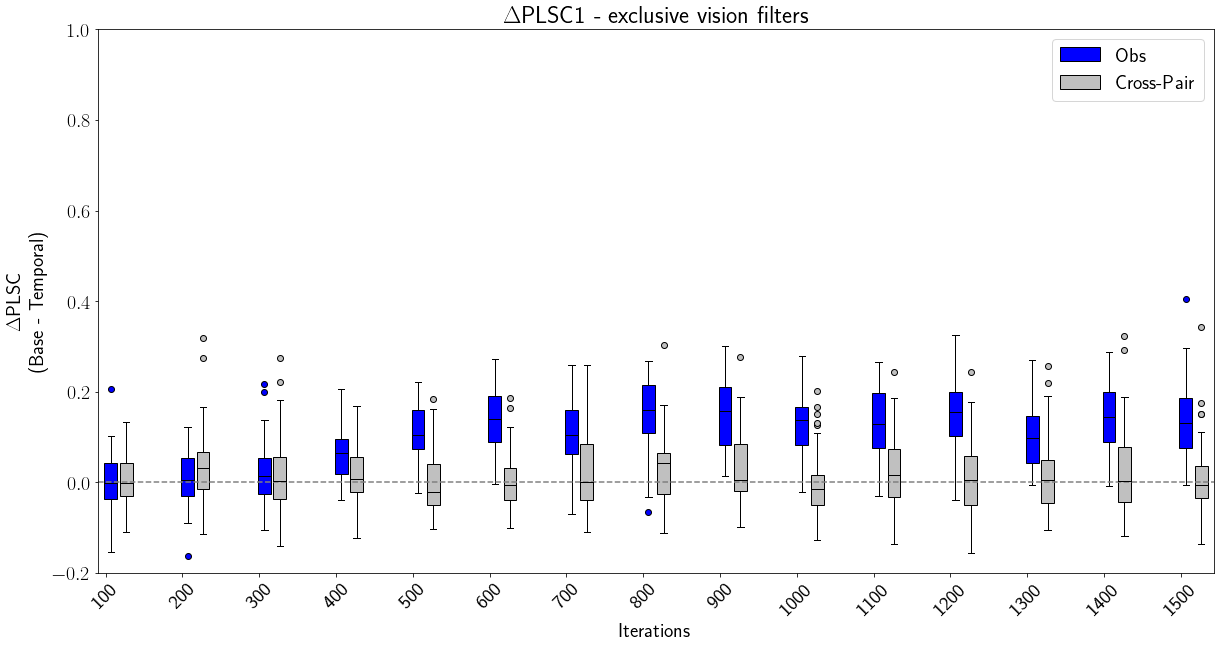

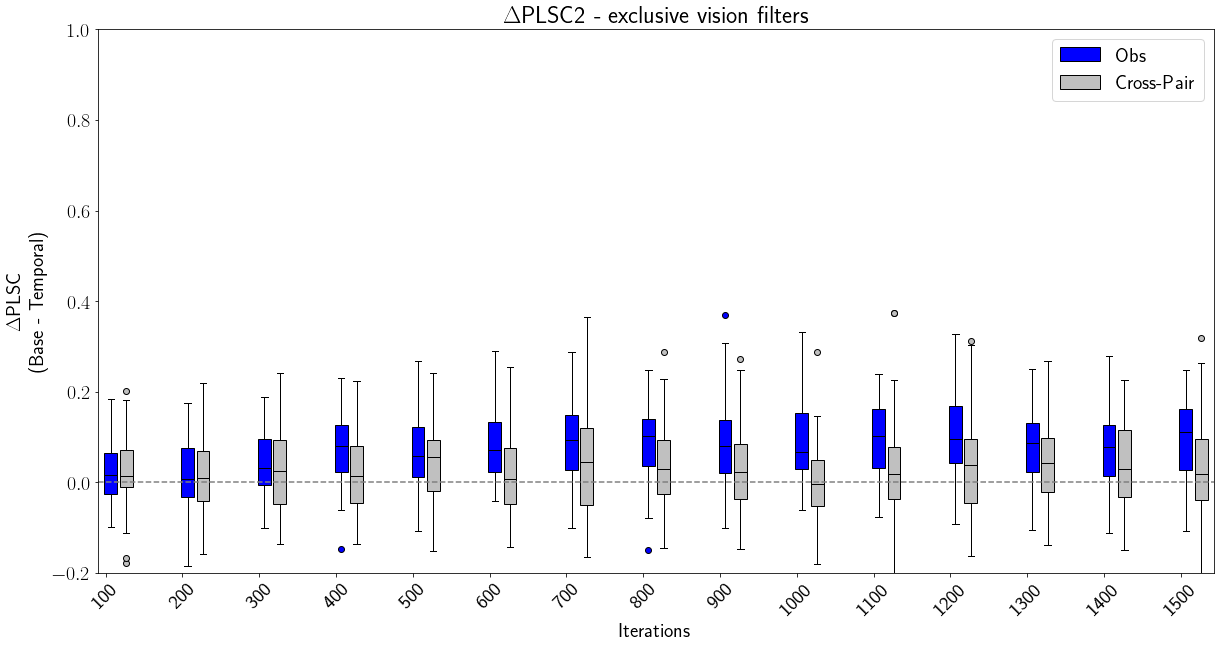

In [12]:
filters_used = [n for n, f in zip(filter_names, [death_filter, mutual_vision_filter, exclusive_vision_filter]) if f]

for i in range(plsc_levels):
    fig = plt.figure(figsize=(20, 10))
    plt.rcParams.update({'font.size': 20,'text.usetex': True})

    # Creating plot
    box_count = delta_corr.shape[0]
    box_width = 0.5
    box_spacing = 3
    bplot2 = plt.boxplot(delta_corr_cp[:,:,i].T, patch_artist=True, flierprops={'markerfacecolor': 'silver'},
                         boxprops=dict(facecolor="silver"),
                         positions=np.arange(box_count) * box_spacing + 0.8, widths=box_width)
    bplot1 = plt.boxplot(delta_corr[:,:,i].T, patch_artist=True, flierprops={'markerfacecolor': 'blue'},
                         boxprops=dict(facecolor="blue"),
                         positions=np.arange(box_count) * box_spacing + 0.2, widths=box_width)

    plt.axhline(y=0, color='gray', linestyle='dashed')
    plt.ylim([-0.2, 1])
    plt.ylabel(r'$\Delta$PLSC'+'\n (Base - Temporal)')
    plt.xlabel('Iterations')
    ticks = np.arange(0, train_iterations * box_spacing, box_spacing)
    plt.xticks(ticks, checkpoint_iters)
    plt.xticks(rotation=45)

    if len(filters_used):
        plt.title(r'$\Delta$PLSC'+f"{i+1} - {','.join(filters_used)} filters")
    else:
        plt.title(r'$\Delta$PLSC'+f'{i+1}')

    plt.legend([bplot1["boxes"][0], bplot2["boxes"][0]], ['Obs', 'Cross-Pair'], loc='upper right')

    # Colour medians
    for plot in [bplot1, bplot2]:
        for median in plot['medians']:
            median.set_color('black')

    # show plot
    chart_dir = f'{checkpoint_range_dir}/charts'
    make_if_not_exists(chart_dir)
    file_name = f"delta_plsc_{i+1}_{','.join(filters_used)}"
    chart_path = f"{chart_dir}/{file_name}.png"
    # As the Delta PLSC is so expensive to compute, we also save the calculated results, in case we need the data later.
    with open(f"{chart_dir}/{file_name}.pkl", 'wb') as f:
        d = {'delta_corr':delta_corr, 'delta_corr_cp': delta_corr_cp}
        pickle.dump(d, f, protocol=pickle.HIGHEST_PROTOCOL)
    plt.savefig(chart_path)
    plt.show()